# Prueba: ¿alcanzan humedad y grasa para separar las familias, sin usar sus rótulos?
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026**

Cuaderno **de prueba**, separado de `trabajo_senasa_mq.ipynb`. Ese notebook agrupa con k-medias en base seca solo las
muestras que tienen **los cuatro análisis** (humedad, grasa, proteínas y cenizas): el 16 % de Senasa (2660 de 16347, el 81 %
dulce de leche), y manda el queso a una rama propia de humedad + grasa. Para decidir si **conviene separar el agrupamiento
en ramas por familia** o alcanza un solo clustering, acá se hace lo contrario: **un solo agrupamiento, sin ramas y sin
rótulos, con las dos variables que casi todas las familias tienen (humedad y grasa)**, sobre *todas* las muestras que las
tienen. Después se compara con la familia del catálogo (`desc_familia`), que **no se usa para ajustar**, solo para evaluar.

**Pregunta:** ¿un agrupamiento no supervisado con solo humedad y grasa separa las familias?

**Cómo se mide (y una advertencia).** Con ARI y AMI contra la familia, más pureza y cobertura por cluster. Dulce de leche y
queso son ~85 % de las muestras que entran, así que el ARI «común» lo domina el par DDL–queso, que es fácil de separar.
Por eso se informa también el **ARI y el AMI balanceados** (hasta 100 muestras por familia, 20 sorteos), que pesan igual a
cada familia. Si los dos difieren mucho, la separación que se ve es la de las familias grandes.

**Referencia superior.** Para saber si un agrupamiento falla por el algoritmo o porque la información no alcanza, se
calcula también una **cota supervisada** (bosque aleatorio con validación cruzada, *con* rótulos): lo mejor que
podrían hacer humedad y grasa si se usaran los rótulos. Es optimista (hay muestras casi repetidas entre pliegues).

Semilla 42. Escribe solo en `resultados/prueba_todas_hg/`. Al final, el **veredicto**.

## 0 · Rutas, parámetros y lectura

In [1]:
import sys
import warnings
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rutas as R
import clustering_todas_hg as T
from datos_clase41 import COLUMNAS, SEMILLA, leer_senasa

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10, "axes.labelsize": 9})
SALIDA = R.RESULTADOS / "prueba_todas_hg"; SALIDA.mkdir(parents=True, exist_ok=True)
PCT = 3                                   # corte de outliers por consenso (el del notebook único)
KS_KM, KS_GMM = range(2, 13), range(1, 13)
DPI = 150
VERSIONES = {"Senasa": False, "Senasa + MQ": True}
VARS = T.VARIABLES                        # {"H + G": [humedad, grasa], "base seca": [humedad, mges]}
S = leer_senasa()
print("Senasa:", len(S.crudo), "muestras · semilla", SEMILLA)

Senasa: 16347 muestras · semilla 42


## 1 · Población: qué muestras entran
**Misma lectura que el notebook único** (`datos_clase41.py`): Senasa manda, MQ solo completa huecos y las muestras solo MQ
salen de `MQ encolumnado.xlsx` (sin las MO, que ya están en Senasa). Se sacan las `FAMILIAS_NO_LACTEAS`, las muestras con
humedad + sólidos totales fuera de 100 ± 1 y, como en el notebook único, el **queso solo MQ cuya familia no confirma el
rótulo** (la familia de MQ sale de un modelo sin revisar). Después, lo propio de esta prueba:

* **Entra** toda muestra con **humedad (o 100 − sólidos totales, en Senasa) y grasa**; se descartan las de valores
  imposibles (humedad < 0 o > 99, grasa < 0, humedad + grasa > 102, el mismo tope de suma del notebook único).
  Humedad > 99 se saca porque la grasa en base seca (÷ (100 − humedad)) se dispara.
* A diferencia del notebook único, **no se piden proteínas ni cenizas**.
* Las muestras sin rótulo de familia (`sin clasificar`, solo MQ `sin familia`) **entran al agrupamiento** pero no cuentan en
  las métricas contra la familia (no se sabe qué son).

In [2]:
POB = {n: T.poblacion(S, con_mq) for n, con_mq in VERSIONES.items()}
flujo = pd.concat({n: POB[n][1] for n in POB}, axis=1)
flujo.astype("Int64")

,Senasa,Senasa + MQ
muestras leídas,16347,30089
humedad de Senasa tomada de 100 − sólidos,2,2
fuera: familia no láctea,1727,2319
fuera: humedad + sólidos fuera de 100 ± 1,8,8
"candidatas (lácteas, sin las excluidas)",14612,26634
"entran (humedad y grasa, valores posibles)",4982,9407
fuera: queso solo MQ sin variedad en el rótulo (familia sin confirmar),<NA>,1128
"de ellas, con humedad y grasa",<NA>,697


In [3]:
for n, (cand, _) in POB.items():
    print(f"=== {n}: {len(cand)} muestras candidatas (lácteas, sin las excluidas) · origen: {cand['origen'].value_counts().to_dict()}")
    t = T.tabla_por_familia(cand)
    display(t.astype({c: int for c in t.columns if c != "% entra"}))
    t.to_csv(SALIDA / f"poblacion_por_familia_{n.replace(' + ', '_').lower()}.csv", encoding="utf-8-sig")

=== Senasa: 14612 muestras candidatas (lácteas, sin las excluidas) · origen: {'Senasa': 14612}


estado,muestras,entra,sin humedad ni grasa,sin humedad,sin grasa,valores imposibles,% entra,con los 4 análisis
familia,,,,,,,,
DDL,4355,2631,718,698,308,0,60.4,2161
queso,4006,1627,2049,0,330,0,40.6,0
leche fluida,2121,21,2100,0,0,0,1.0,0
leche en polvo,1406,100,1306,0,0,0,7.1,100
suero,986,57,929,0,0,0,5.8,57
helado,676,12,549,113,2,0,1.8,3
conc. proteico,651,326,325,0,0,0,50.1,326
yogur,178,18,157,3,0,0,10.1,11
manteca / crema,156,145,11,0,0,0,92.9,0


=== Senasa + MQ: 26634 muestras candidatas (lácteas, sin las excluidas) · origen: {'Senasa': 13938, 'solo MQ': 12022, 'Senasa completada con MQ': 674}


estado,muestras,entra,sin humedad ni grasa,sin humedad,sin grasa,valores imposibles,% entra,con los 4 análisis
familia,,,,,,,,
queso,5915,2891,2344,148,531,1,48.9,75
leche en polvo,5637,1565,2847,831,394,0,27.8,681
DDL,4467,2704,714,712,337,0,60.5,2233
leche fluida,2951,346,2278,173,154,0,11.7,148
suero,2328,530,1010,356,425,7,22.8,263
manteca / crema,1337,275,108,861,90,3,20.6,8
sin clasificar,1302,172,231,719,180,0,13.2,57
conc. proteico,1111,462,395,85,169,0,41.6,390
helado,759,54,462,220,23,0,7.1,4


In [4]:
for n, (cand, _) in POB.items():
    t = T.tabla_por_familia(cand)
    lf = t.loc["leche fluida"]; tot = t.loc["total"]
    print(f"{n}: entran {int(tot['entra'])} de {int(tot['muestras'])} ({tot['% entra']} %). La leche fluida casi no entra: "
          f"{int(lf['entra'])} de {int(lf['muestras'])} ({lf['% entra']} %), porque en Senasa no se pide humedad ni grasa en leche fluida "
          f"({int(lf['sin humedad ni grasa'])} sin ninguna de las dos).")
    resto = t.drop(index=["total"]).sort_values("% entra")
    print("   familias con menos del 10 % adentro:", ", ".join(f"{f} ({r['% entra']} %)" for f, r in resto.iterrows() if r["% entra"] < 10))

Senasa: entran 4982 de 14612 (34.1 %). La leche fluida casi no entra: 21 de 2121 (1.0 %), porque en Senasa no se pide humedad ni grasa en leche fluida (2100 sin ninguna de las dos).
   familias con menos del 10 % adentro: leche fluida (1.0 %), helado (1.8 %), suero (5.8 %), leche en polvo (7.1 %), sin clasificar (9.1 %)
Senasa + MQ: entran 9407 de 26634 (35.3 %). La leche fluida casi no entra: 346 de 2951 (11.7 %), porque en Senasa no se pide humedad ni grasa en leche fluida (2278 sin ninguna de las dos).
   familias con menos del 10 % adentro: helado (7.1 %)


## 2 · Variables y outliers
**Dos variantes**, las dos estandarizadas (media 0, desvío 1):

* **H + G**: humedad y materia grasa en g/100 g (lo medido).
* **base seca**: humedad y MGES = grasa / (100 − humedad) × 100 (materia grasa en el extracto seco, la medida del CAA).

La MGES saca de la grasa el efecto de cuánta agua hay: un queso y un polvo con la misma MGES pueden tener 5 y 50 g de grasa por
100 g.

**Outliers**: el mismo criterio de consenso del notebook único (`mejoras_clustering.outliers_consenso`): k-medias preliminar
(k por silueta, 2 a 10) como grupos y, dentro de cada uno, factor local (50 vecinos), bosque de aislamiento y elipse, cada
uno marca el 3 % más raro; outlier si lo marcan al menos 2 de 3. Funciona igual con 2 variables. Se detectan **una vez, en
H + G (g/100 g)**, y se sacan en las dos variantes, para que las dos comparen las mismas muestras.

In [5]:
DAT = {}
for n, (cand, _) in POB.items():
    pop = cand[cand["estado"] == "entra"].reset_index(drop=True)
    es, votos, grupos, k_pre = T.outliers(pop[["humedad", "grasa"]].to_numpy(), pct=PCT)
    pop["outlier"] = es
    DAT[n] = dict(pop=pop, d=pop[~es].reset_index(drop=True), k_pre=k_pre)
    print(f"{n}: k-medias preliminar k = {k_pre} · outliers {int(es.sum())} de {len(pop)} ({100 * es.mean():.1f} %) · quedan {len(pop) - int(es.sum())}")
    display(pop.groupby("familia").agg(entran=("outlier", "size"), outliers=("outlier", "sum")).assign(**{"% outliers": lambda t: (100 * t["outliers"] / t["entran"]).round(1)}).sort_values("entran", ascending=False).T)

Senasa: k-medias preliminar k = 6 · outliers 113 de 4982 (2.3 %) · quedan 4869


familia,DDL,queso,conc. proteico,manteca / crema,leche en polvo,suero,postre,leche fluida,yogur,helado,sin clasificar
entran,2631.0,1627.0,326.0,145.0,100.0,57.0,43.0,21.0,18.0,12.0,2.0
outliers,47.0,39.0,4.0,5.0,0.0,5.0,0.0,0.0,8.0,5.0,0.0
% outliers,1.8,2.4,1.2,3.4,0.0,8.8,0.0,0.0,44.4,41.7,0.0


Senasa + MQ: k-medias preliminar k = 6 · outliers 211 de 9407 (2.2 %) · quedan 9196


familia,queso,DDL,leche en polvo,suero,conc. proteico,leche fluida,yogur,manteca / crema,sin clasificar,postre,helado
entran,2891.0,2704.0,1565.0,530.0,462.0,346.0,337.0,275.0,172.0,71.0,54.0
outliers,55.0,19.0,7.0,9.0,13.0,7.0,15.0,46.0,23.0,0.0,17.0
% outliers,1.9,0.7,0.4,1.7,2.8,2.0,4.5,16.7,13.4,0.0,31.5


In [6]:
d = DAT["Senasa + MQ"]["d"]
print("Correlación de Pearson, humedad vs grasa:", round(d[["humedad", "grasa"]].corr().iat[0, 1], 2), "· humedad vs MGES:", round(d[["humedad", "mges"]].corr().iat[0, 1], 2))
print(f"MGES: rango {d['mges'].min():.1f} a {d['mges'].max():.1f} (mediana {d['mges'].median():.1f})")
d.groupby("familia")[["humedad", "grasa", "mges"]].median().round(1).assign(muestras=d["familia"].value_counts()).sort_values("humedad")

Correlación de Pearson, humedad vs grasa: -0.23 · humedad vs MGES: 0.09
MGES: rango 0.0 a 100.0 (mediana 17.4)


,humedad,grasa,mges,muestras
familia,,,,
leche en polvo,2.8,27.0,27.8,1558
conc. proteico,4.2,3.1,3.5,449
manteca / crema,15.0,83.2,97.8,229
DDL,28.0,6.8,9.4,2685
sin clasificar,31.2,7.6,11.0,149
queso,44.5,26.4,46.0,2836
helado,60.5,8.1,20.5,37
postre,69.4,3.2,10.5,71
suero,81.2,0.4,1.3,521


## 3 · Modelos sin rótulos
Sobre cada versión (solo Senasa; Senasa + MQ) y cada variante (H + G; base seca):

* **k-medias**: k por **silueta** máxima (2 a 12; silueta sobre 10 000 muestras al azar fijas) y k del **codo** de la
  inercia (el de mayor distancia a la recta entre los extremos de la curva).
* **Mezcla de gaussianas** (covarianza completa, n_init 3): k por **BIC** mínimo (1 a 12).
* **HDBSCAN** (opcional): `min_cluster_size` 50, 100, 200 y 400; se elige sin mirar la familia, el número de grupos más
  frecuente en la grilla y, entre los que lo dan, el menor tamaño. El ruido (−1) es un grupo más al evaluar.
* **Referencia**: k-medias y mezcla con **k = número de familias** (no usa los rótulos, solo cuántos hay).

In [7]:
def correr(d, variables):
    Z, _ = T.estandarizar(d[variables].to_numpy())
    bk = T.barrido_kmedias(Z, KS_KM); bg = T.barrido_gmm(Z, KS_GMM); hd = T.barrido_hdbscan(Z)
    h = d["humedad"].to_numpy(); n_fam = int(d["fam_eval"].nunique())
    et, meta = {}, {}
    def add(nombre, e, tipo, ref=False):
        et[nombre] = T.ordenar(e, h); meta[nombre] = dict(tipo=tipo, ref=ref)
    add(f"k-medias k={bk['k_sil']} (silueta)", bk["modelos"][bk["k_sil"]].labels_, "km")
    if bk["k_codo"] != bk["k_sil"]:
        add(f"k-medias k={bk['k_codo']} (codo)", bk["modelos"][bk["k_codo"]].labels_, "km")
    add(f"GMM k={bg['k_bic']} (BIC)", bg["modelos"][bg["k_bic"]].predict(Z), "gmm")
    add(f"HDBSCAN (min {hd['m']})", hd["elegida"], "hdb")
    add(f"k-medias k={n_fam} (= nº de familias)", bk["modelos"][n_fam].labels_, "km", ref=True)
    add(f"GMM k={n_fam} (= nº de familias)", bg["modelos"][n_fam].predict(Z), "gmm", ref=True)
    return dict(Z=Z, bk=bk, bg=bg, hd=hd, et=et, meta=meta, n_fam=n_fam)

RES = {(n, v): correr(DAT[n]["d"], VARS[v]) for n in VERSIONES for v in VARS}
filas = []
for (n, v), r in RES.items():
    filas.append({"versión": n, "variables": v, "muestras": len(r["Z"]), "k-medias (silueta)": r["bk"]["k_sil"], "k-medias (codo)": r["bk"]["k_codo"],
                  "GMM (BIC)": r["bg"]["k_bic"], "HDBSCAN: grupos": len(set(r["hd"]["elegida"]) - {-1}), "HDBSCAN: ruido": int((r["hd"]["elegida"] == -1).sum()),
                  "silueta máx.": round(max(r["bk"]["silueta"].values()), 3), "nº de familias": r["n_fam"]})
pd.DataFrame(filas).set_index(["versión", "variables"])

muestras  k-medias (silueta)  k-medias (codo)  GMM (BIC)  HDBSCAN: grupos  HDBSCAN: ruido  silueta máx.  nº de familias
versión     variables                                                                                                                         
Senasa      H + G          4869                   6                5         12                7             127         0.799              10
            base seca      4869                   5                5         12                7             143         0.774              10
Senasa + MQ H + G          9196                   6                5         11               12             458         0.757              10
            base seca      9196                   6                5          9                5             575         0.766              10

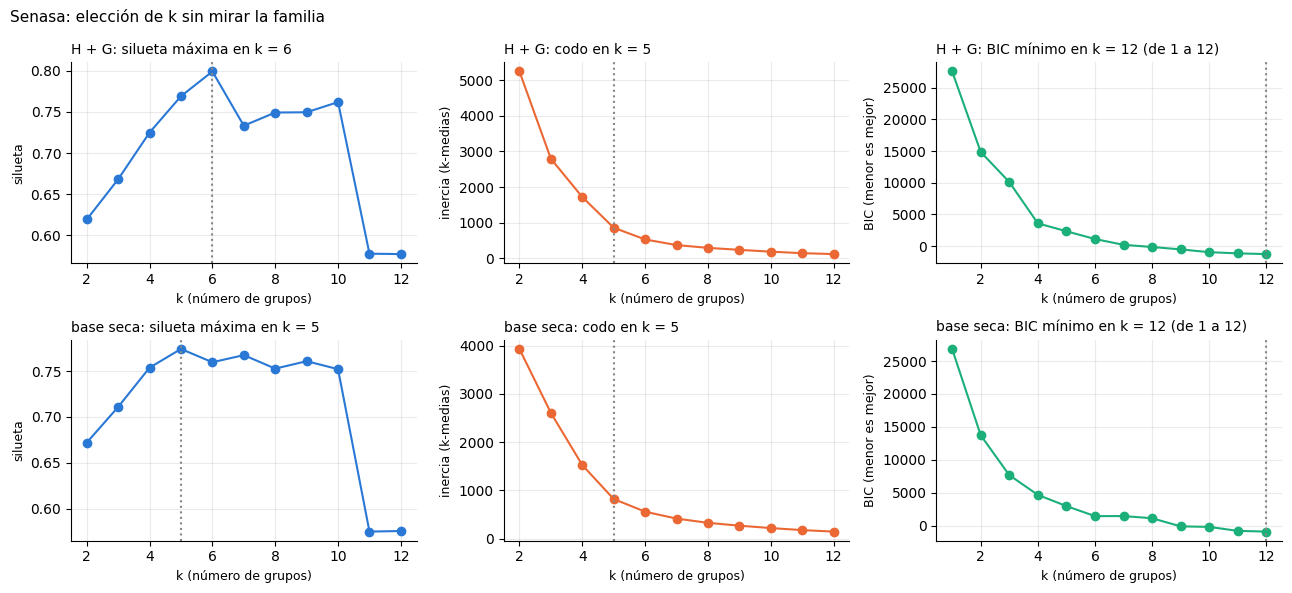

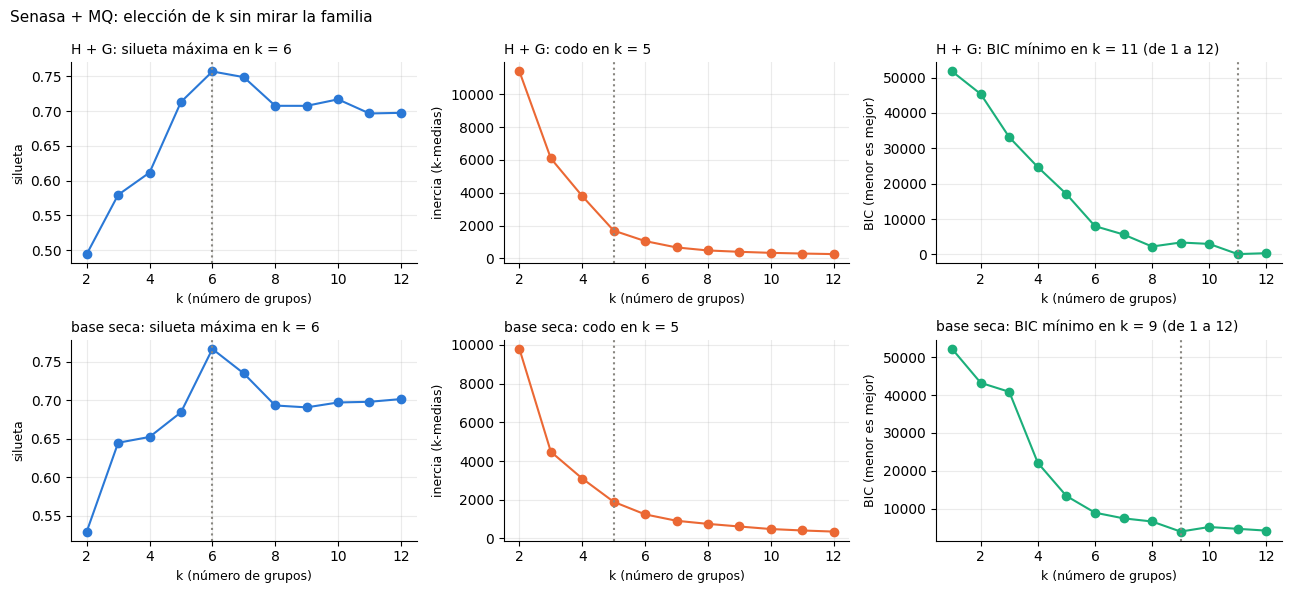

In [8]:
for n in VERSIONES:
    fig, ax = plt.subplots(2, 3, figsize=(13, 6))
    for i, v in enumerate(VARS):
        r = RES[(n, v)]; bk, bg = r["bk"], r["bg"]
        ax[i, 0].plot(list(bk["silueta"]), list(bk["silueta"].values()), "o-", color="#2a78d6"); ax[i, 0].axvline(bk["k_sil"], color="#898781", ls=":")
        ax[i, 0].set_title(f"{v}: silueta máxima en k = {bk['k_sil']}", loc="left"); ax[i, 0].set_ylabel("silueta")
        ax[i, 1].plot(list(bk["inercia"]), list(bk["inercia"].values()), "o-", color="#eb6834"); ax[i, 1].axvline(bk["k_codo"], color="#898781", ls=":")
        ax[i, 1].set_title(f"{v}: codo en k = {bk['k_codo']}", loc="left"); ax[i, 1].set_ylabel("inercia (k-medias)")
        ax[i, 2].plot(list(bg["bic"]), list(bg["bic"].values()), "o-", color="#1baf7a"); ax[i, 2].axvline(bg["k_bic"], color="#898781", ls=":")
        ax[i, 2].set_title(f"{v}: BIC mínimo en k = {bg['k_bic']} (de 1 a 12)", loc="left"); ax[i, 2].set_ylabel("BIC (menor es mejor)")
        for a in ax[i]: a.set_xlabel("k (número de grupos)"); a.grid(alpha=0.25)
    fig.suptitle(f"{n}: elección de k sin mirar la familia", fontsize=11, x=0.01, ha="left")
    fig.tight_layout(); fig.savefig(SALIDA / f"seleccion_k_{n.replace(' + ', '_').lower()}.png", dpi=DPI); plt.show()

Si el BIC de la mezcla toca el borde de la grilla (k = 12), la mezcla está aproximando una **densidad continua** con más y
más componentes, no encontrando un número «verdadero» de grupos: es un dato más para no leer sus clusters como tipos de
producto.

## 4 · Evaluación contra la familia
`desc_familia` solo se usa acá. **Pureza**: parte del cluster que es de su familia mayoritaria; **cobertura**: parte de esa
familia que cayó en ese cluster. Las muestras sin rótulo no cuentan. **ARI** y **AMI** (1 = misma partición; 0 = azar);
«balanceado» = hasta 100 muestras por familia, promedio de 20 sorteos. La silueta es interna (no usa la familia).

In [9]:
filas = []
for (n, v), r in RES.items():
    f = DAT[n]["d"]["fam_eval"]
    for nombre, e in r["et"].items():
        m = T.evaluar(r["Z"], e, f, r["bk"]["idx"])
        filas.append({"versión": n, "variables": v, "modelo": nombre, "referencia": r["meta"][nombre]["ref"], **m})
EVAL = pd.DataFrame(filas)
EVAL.to_csv(SALIDA / "evaluacion_modelos.csv", index=False, encoding="utf-8-sig")
cols = ["grupos", "ruido", "ARI", "AMI", "ARI balanceado", "AMI balanceado", "pureza global", "pureza macro", "cobertura macro", "silueta", "silueta macro"]
for n in VERSIONES:
    print(f"=== {n} (las filas «= nº de familias» son referencia: usan cuántas familias hay)")
    display(EVAL[EVAL["versión"] == n].set_index(["variables", "modelo"])[cols].round(3))

=== Senasa (las filas «= nº de familias» son referencia: usan cuántas familias hay)


grupos  ruido    ARI    AMI  ARI balanceado  AMI balanceado  pureza global  pureza macro  cobertura macro  silueta  silueta macro
variables modelo                                                                                                                                                             
H + G     k-medias k=6 (silueta)                 6      0  0.930  0.866           0.693           0.796          0.951         0.827            0.912    0.799          0.768
          k-medias k=5 (codo)                    5      0  0.943  0.885           0.612           0.798          0.949         0.861            0.956    0.769          0.749
          GMM k=12 (BIC)                        12      0  0.625  0.731           0.637           0.793          0.978         0.953            0.852    0.566          0.660
          HDBSCAN (min 50)                       7    127  0.937  0.881           0.710           0.814          0.965         0.883            0.913    0.796          0.865
          k-medias k=10 (= nº de familias)      10      0  0.829  0.798           0.663           0.795          0.974         0.923            0.870    0.762          0.715
          GMM k=10 (= nº de familias)           10      0  0.631  0.737           0.621           0.777          0.974         0.923            0.850    0.539          0.585
base seca k-medias k=5 (silueta)                 5      0  0.893  0.835           0.602           0.785          0.933         0.849            0.952    0.774          0.740
          GMM k=12 (BIC)                        12      0  0.623  0.730           0.636           0.793          0.978         0.952            0.852    0.575          0.668
          HDBSCAN (min 50)                       7    143  0.937  0.879           0.708           0.812          0.965         0.892            0.914    0.788          0.863
          k-medias k=10 (= nº de familias)      10      0  0.827  0.796           0.657           0.787          0.974         0.924            0.855    0.752          0.716
          GMM k=10 (= nº de familias)           10      0  0.827  0.796           0.657           0.789          0.974         0.922            0.870    0.734          0.654

=== Senasa + MQ (las filas «= nº de familias» son referencia: usan cuántas familias hay)


grupos  ruido    ARI    AMI  ARI balanceado  AMI balanceado  pureza global  pureza macro  cobertura macro  silueta  silueta macro
variables modelo                                                                                                                                                             
H + G     k-medias k=6 (silueta)                 6      0  0.787  0.742           0.360           0.621          0.798         0.755            0.850    0.757          0.791
          k-medias k=5 (codo)                    5      0  0.652  0.652           0.306           0.553          0.757         0.772            0.850    0.713          0.766
          GMM k=11 (BIC)                        11      0  0.712  0.737           0.456           0.654          0.856         0.777            0.695    0.636          0.529
          HDBSCAN (min 50)                      12    458  0.827  0.779           0.505           0.700          0.867         0.830            0.767    0.697          0.757
          k-medias k=10 (= nº de familias)      10      0  0.680  0.734           0.429           0.656          0.847         0.832            0.739    0.717          0.679
          GMM k=10 (= nº de familias)           10      0  0.668  0.731           0.462           0.682          0.845         0.814            0.778    0.658          0.579
base seca k-medias k=6 (silueta)                 6      0  0.852  0.783           0.421           0.659          0.830         0.759            0.864    0.766          0.758
          k-medias k=5 (codo)                    5      0  0.718  0.700           0.362           0.596          0.791         0.777            0.868    0.684          0.699
          GMM k=9 (BIC)                          9      0  0.743  0.738           0.448           0.645          0.840         0.772            0.772    0.641          0.531
          HDBSCAN (min 200)                      5    575  0.875  0.789           0.434           0.630          0.831         0.688            0.826    0.801          0.827
          k-medias k=10 (= nº de familias)      10      0  0.748  0.749           0.455           0.653          0.846         0.780            0.739    0.697          0.661
          GMM k=10 (= nº de familias)           10      0  0.764  0.755           0.465           0.665          0.846         0.787            0.755    0.687          0.647

**Sensibilidad al k.** ARI y AMI balanceados para cada k, con k-medias y con la mezcla, en las dos variantes. Muestra si el
resultado depende de haber elegido ese k.

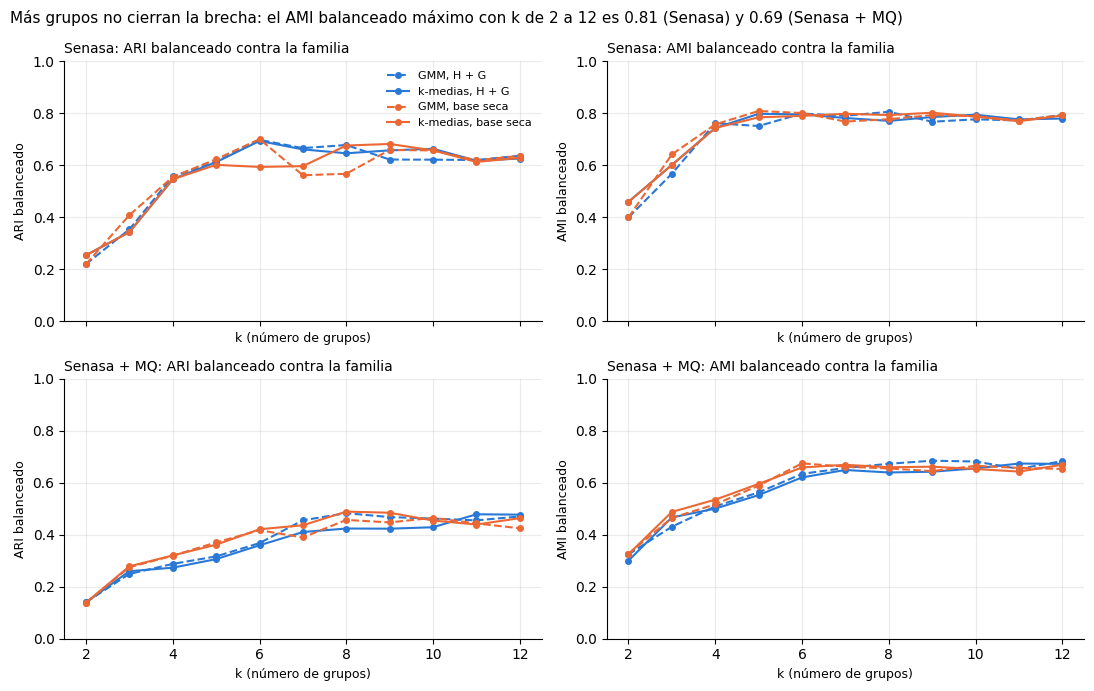

k  ARI balanceado  AMI balanceado
versión     variables algoritmo                                    
Senasa      H + G     GMM         8           0.678           0.806
                      k-medias    5           0.612           0.798
            base seca GMM         5           0.623           0.809
                      k-medias    9           0.682           0.802
Senasa + MQ H + G     GMM         9           0.468           0.685
                      k-medias   11           0.479           0.674
            base seca GMM         6           0.418           0.675
                      k-medias   12           0.464           0.670

In [10]:
filas = []
for (n, v), r in RES.items():
    f = DAT[n]["d"]["fam_eval"]
    for k in KS_KM:
        a, b = T.balanceado(r["bk"]["modelos"][k].labels_[f.notna().to_numpy()], f[f.notna()].to_numpy())
        filas.append({"versión": n, "variables": v, "algoritmo": "k-medias", "k": k, "ARI balanceado": a, "AMI balanceado": b})
    for k in range(2, 13):
        e = r["bg"]["modelos"][k].predict(r["Z"])
        a, b = T.balanceado(e[f.notna().to_numpy()], f[f.notna()].to_numpy())
        filas.append({"versión": n, "variables": v, "algoritmo": "GMM", "k": k, "ARI balanceado": a, "AMI balanceado": b})
SENS = pd.DataFrame(filas); SENS.to_csv(SALIDA / "sensibilidad_k.csv", index=False, encoding="utf-8-sig")
COL_V = {"H + G": "#2a78d6", "base seca": "#eb6834"}; LS = {"k-medias": "-", "GMM": "--"}
fig, ax = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for i, n in enumerate(VERSIONES):
    for j, met in enumerate(["ARI balanceado", "AMI balanceado"]):
        for (v, alg), g in SENS[SENS["versión"] == n].groupby(["variables", "algoritmo"]):
            ax[i, j].plot(g["k"], g[met], LS[alg], marker="o", ms=4, color=COL_V[v], label=f"{alg}, {v}")
        ax[i, j].set_title(f"{n}: {met} contra la familia", loc="left"); ax[i, j].set_ylabel(met); ax[i, j].set_ylim(0, 1); ax[i, j].grid(alpha=0.25)
        ax[i, j].set_xlabel("k (número de grupos)")
ax[0, 0].legend(frameon=False, fontsize=8)
mx = SENS.groupby("versión")["AMI balanceado"].max()
fig.suptitle("Más grupos no cierran la brecha: el AMI balanceado máximo con k de 2 a 12 es " + " y ".join(f"{mx[n]:.2f} ({n})" for n in VERSIONES),
             fontsize=11, x=0.01, ha="left")
fig.tight_layout(); fig.savefig(SALIDA / "sensibilidad_k.png", dpi=DPI); plt.show()
SENS.loc[SENS.groupby(["versión", "variables", "algoritmo"])["AMI balanceado"].idxmax()].round(3).set_index(["versión", "variables", "algoritmo"])

### 4.1 · El mejor modelo (con k elegido sin mirar la familia)
Entre los modelos que **eligen su k solos** (k-medias por silueta o codo, mezcla por BIC y HDBSCAN; se dejan afuera las
referencias «= nº de familias»), el de **mayor ARI balanceado** en cada versión. Elegir por ARI es mirar los rótulos *después*
de ajustar, solo para decidir cuál mostrar. Acá se ve la tabla cluster × familia y el gráfico humedad × grasa.

In [11]:
MEJOR = {}
for n in VERSIONES:
    e = EVAL[(EVAL["versión"] == n) & ~EVAL["referencia"]].sort_values("ARI balanceado", ascending=False).iloc[0]
    MEJOR[n] = (e["variables"], e["modelo"])
    print(f"{n}: mejor = {e['modelo']} con variables «{e['variables']}» · ARI {e['ARI']:.3f} (balanceado {e['ARI balanceado']:.3f}) · AMI {e['AMI']:.3f} (balanceado {e['AMI balanceado']:.3f})")

Senasa: mejor = HDBSCAN (min 50) con variables «H + G» · ARI 0.937 (balanceado 0.710) · AMI 0.881 (balanceado 0.814)
Senasa + MQ: mejor = HDBSCAN (min 50) con variables «H + G» · ARI 0.827 (balanceado 0.505) · AMI 0.779 (balanceado 0.700)


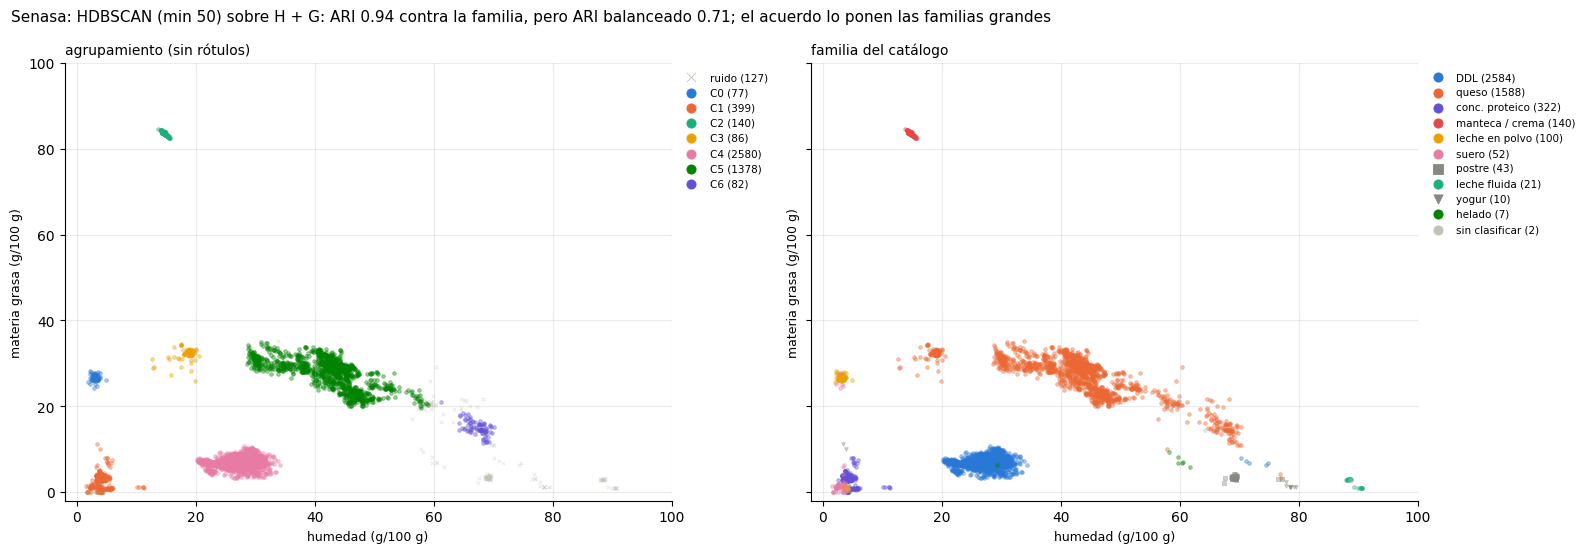

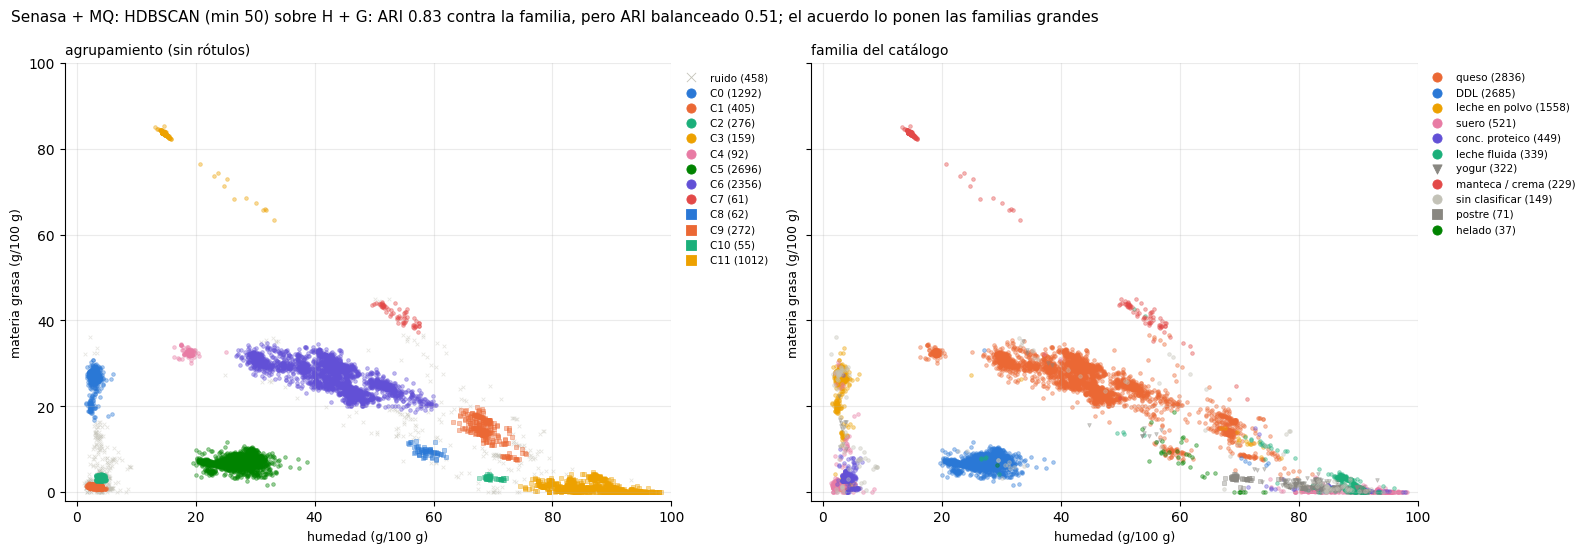

In [12]:
def figura(n, v, nombre, archivo):
    r = RES[(n, v)]; d = DAT[n]["d"]; e = r["et"][nombre]
    ct = T.reparto_familia(e, d["fam_eval"])
    fig, ax = plt.subplots(1, 2, figsize=(16, 5.6), sharex=True, sharey=True)
    T.grafico_lado_a_lado(d, e, "", ax)
    ax[0].set_xlim(-2, 100); ax[0].set_ylim(-2, 100)
    ev = EVAL[(EVAL["versión"] == n) & (EVAL["variables"] == v) & (EVAL["modelo"] == nombre)].iloc[0]
    fig.suptitle(f"{n}: {nombre} sobre {v}: ARI {ev['ARI']:.2f} contra la familia, pero ARI balanceado {ev['ARI balanceado']:.2f}; el acuerdo lo ponen las familias grandes",
                 fontsize=11, x=0.01, ha="left")
    fig.tight_layout(); fig.savefig(SALIDA / archivo, dpi=DPI); plt.show()

for n, (v, nombre) in MEJOR.items():
    figura(n, v, nombre, f"mejor_modelo_{n.replace(' + ', '_').lower()}.png")

In [13]:
CRUZ = {}
for n, (v, nombre) in MEJOR.items():
    r = RES[(n, v)]; d = DAT[n]["d"]; e = r["et"][nombre]; f = d["fam_eval"]
    pc = T.por_cluster(d, e, f, r["Z"], r["bk"]["idx"]); cr = T.cruzada(e, f)
    CRUZ[n] = (pc, cr)
    pc.to_csv(SALIDA / f"por_cluster_{n.replace(' + ', '_').lower()}.csv", encoding="utf-8-sig"); cr.to_csv(SALIDA / f"cruzada_{n.replace(' + ', '_').lower()}.csv", encoding="utf-8-sig")
    print(f"=== {n}: {nombre} sobre {v}. Por cluster (humedad y grasa medianas en g/100 g; pureza y cobertura en %)")
    display(pc.round({"humedad": 1, "grasa": 1, "pureza %": 0, "cobertura %": 0, "silueta": 2}))
    print("Cluster × familia, % de cada cluster (n = muestras con rótulo)")
    display(cr)

=== Senasa: HDBSCAN (min 50) sobre H + G. Por cluster (humedad y grasa medianas en g/100 g; pureza y cobertura en %)


,muestras,humedad,grasa,familia mayoritaria,pureza %,cobertura %,segunda familia,silueta
ruido,127,69.14,3.58,postre,34.126984,100.0,queso (34 %),NaN
C0,77,3.13,26.63,leche en polvo,92.207792,71.0,suero (6 %),0.940427
C1,399,4.08,3.04,conc. proteico,80.451128,99.689441,suero (12 %),0.910262
C2,140,14.69,83.655,manteca / crema,100.0,100.0,-,0.986621
C3,86,18.98,32.225,queso,100.0,5.415617,-,0.864768
C4,2580,27.985,6.83,DDL,99.96124,99.806502,helado (0 %),0.870841
C5,1378,43.51,28.36,queso,100.0,86.775819,-,0.586226
C6,82,67.715,14.8,queso,100.0,5.100756,-,0.898424


Cluster × familia, % de cada cluster (n = muestras con rótulo)


col_0,n,DDL,conc. proteico,helado,leche en polvo,leche fluida,manteca / crema,postre,queso,suero,yogur
ruido,126,4.0,0.0,5.0,0.0,17.0,0.0,34.0,34.0,0.0,6.0
C0,77,0.0,1.0,0.0,92.0,0.0,0.0,0.0,0.0,6.0,0.0
C1,399,0.0,80.0,0.0,7.0,0.0,0.0,0.0,0.0,12.0,1.0
C2,140,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0
C3,86,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0
C4,2580,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
C5,1378,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0
C6,81,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0


=== Senasa + MQ: HDBSCAN (min 50) sobre H + G. Por cluster (humedad y grasa medianas en g/100 g; pureza y cobertura en %)


,muestras,humedad,grasa,familia mayoritaria,pureza %,cobertura %,segunda familia,silueta
ruido,458,5.87,7.885,queso,25.728155,3.737659,conc. proteico (23 %),NaN
C0,1292,2.74,27.24,leche en polvo,98.970705,80.231065,suero (1 %),0.863698
C1,405,3.38,1.19,leche en polvo,58.5,15.019255,suero (40 %),0.688532
C2,276,4.09,3.225,conc. proteico,98.545455,60.356347,leche en polvo (1 %),0.735133
C3,159,14.72,83.6,manteca / crema,100.0,69.432314,-,0.927284
C4,92,18.98,32.385,queso,100.0,3.244006,-,0.896782
C5,2696,28.01,6.82,DDL,99.776536,99.776536,leche fluida (0 %),0.846599
C6,2356,43.715,27.45,queso,99.616205,82.369535,yogur (0 %),0.451398
C7,61,54.1,41.6,manteca / crema,96.721311,25.764192,leche fluida (3 %),0.824303
C8,62,58.6,9.405,queso,77.04918,1.657264,helado (21 %),0.789665


Cluster × familia, % de cada cluster (n = muestras con rótulo)


col_0,n,DDL,conc. proteico,helado,leche en polvo,leche fluida,manteca / crema,postre,queso,suero,yogur
ruido,412,1.0,23.0,6.0,13.0,4.0,2.0,1.0,26.0,17.0,6.0
C0,1263,0.0,0.0,0.0,99.0,0.0,0.0,0.0,0.0,1.0,0.0
C1,400,0.0,2.0,0.0,58.0,0.0,0.0,0.0,0.0,40.0,0.0
C2,275,0.0,99.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
C3,159,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0
C4,92,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0
C5,2685,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
C6,2345,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0
C7,61,0.0,0.0,0.0,0.0,3.0,97.0,0.0,0.0,0.0,0.0
C8,61,0.0,0.0,21.0,0.0,0.0,0.0,0.0,77.0,0.0,2.0


**Sensibilidad al rótulo de MQ.** En Senasa + MQ la familia de las muestras solo MQ sale de un modelo sin revisar a mano
(`mq_tipo_muestra.csv`), así que es una referencia más floja que la de Senasa. Misma evaluación, **solo con las muestras de
Senasa** (rótulo revisado) y con todas, para los modelos con k propio.

In [14]:
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score
n = "Senasa + MQ"; d = DAT[n]["d"]; f = d["fam_eval"].to_numpy(dtype=object)
ok_sen = (d["origen"] != "solo MQ").to_numpy() & d["fam_eval"].notna().to_numpy(); ok_todas = d["fam_eval"].notna().to_numpy()
filas = []
for v in VARS:
    r = RES[(n, v)]
    for nombre, e in r["et"].items():
        if r["meta"][nombre]["ref"]:
            continue
        fila = {"variables": v, "modelo": nombre}
        for nom, ok in [("solo Senasa", ok_sen), ("todas", ok_todas)]:
            b = T.balanceado(e[ok], f[ok])
            fila.update({f"{nom}: n": int(ok.sum()), f"{nom}: ARI": adjusted_rand_score(f[ok], e[ok]), f"{nom}: AMI": adjusted_mutual_info_score(f[ok], e[ok]),
                         f"{nom}: ARI bal.": b[0], f"{nom}: AMI bal.": b[1]})
        filas.append(fila)
SOLO_SEN = pd.DataFrame(filas).set_index(["variables", "modelo"]); SOLO_SEN.to_csv(SALIDA / "sensibilidad_rotulo_mq.csv", encoding="utf-8-sig")
SOLO_SEN.round(3)

solo Senasa: n  solo Senasa: ARI  solo Senasa: AMI  solo Senasa: ARI bal.  solo Senasa: AMI bal.  todas: n  todas: ARI  todas: AMI  todas: ARI bal.  todas: AMI bal.
variables modelo                                                                                                                                                                                      
H + G     k-medias k=6 (silueta)            5568             0.922             0.816                  0.515                  0.697      9047       0.787       0.742            0.360            0.621
          k-medias k=5 (codo)               5568             0.725             0.695                  0.401                  0.616      9047       0.652       0.652            0.306            0.553
          GMM k=11 (BIC)                    5568             0.859             0.797                  0.554                  0.715      9047       0.712       0.737            0.456            0.654
          HDBSCAN (min 50)                  5568             0.930             0.834                  0.634                  0.749      9047       0.827       0.779            0.505            0.700
base seca k-medias k=6 (silueta)            5568             0.943             0.841                  0.524                  0.700      9047       0.852       0.783            0.421            0.659
          k-medias k=5 (codo)               5568             0.749             0.725                  0.415                  0.623      9047       0.718       0.700            0.362            0.596
          GMM k=9 (BIC)                     5568             0.878             0.795                  0.547                  0.701      9047       0.743       0.738            0.448            0.645
          HDBSCAN (min 200)                 5568             0.958             0.844                  0.502                  0.655      9047       0.875       0.789            0.434            0.630

## 5 · Estabilidad
**Entre semillas**: 10 corridas con una sola inicialización cada una (con n_init alto la inicialización se compensa; acá se
mide cuánto cambia si no se compensa), ARI entre todos los pares. **Bootstrap**: 20 remuestreos con reposición; se ajusta
con cada uno, se asignan todas las muestras y se compara (ARI) con la partición original. El k es el elegido por silueta
(k-medias) o BIC (mezcla).

In [15]:
filas = []
for (n, v), r in RES.items():
    for tipo, nombre in [("km", f"k-medias k={r['bk']['k_sil']} (silueta)"), ("gmm", f"GMM k={r['bg']['k_bic']} (BIC)")]:
        k = r["bk"]["k_sil"] if tipo == "km" else r["bg"]["k_bic"]
        est = T.estabilidad(r["Z"], k, tipo, r["et"][nombre], semillas=range(10), n_boot=20)
        filas.append({"versión": n, "variables": v, "modelo": nombre, **est})
ESTAB = pd.DataFrame(filas); ESTAB.to_csv(SALIDA / "estabilidad.csv", index=False, encoding="utf-8-sig")
ESTAB.set_index(["versión", "variables", "modelo"]).round(3)

semillas: ARI medio  semillas: ARI mínimo  bootstrap: ARI medio  bootstrap: ARI mínimo  bootstrap: desvío
versión     variables modelo                                                                                                                           
Senasa      H + G     k-medias k=6 (silueta)                0.968                 0.939                 0.987                  0.939              0.021
                      GMM k=12 (BIC)                        0.977                 0.950                 0.907                  0.569              0.144
            base seca k-medias k=5 (silueta)                0.970                 0.854                 0.997                  0.992              0.002
                      GMM k=12 (BIC)                        0.939                 0.752                 0.937                  0.576              0.097
Senasa + MQ H + G     k-medias k=6 (silueta)                0.858                 0.711                 0.988                  0.789              0.046
                      GMM k=11 (BIC)                        0.863                 0.750                 0.902                  0.826              0.036
            base seca k-medias k=6 (silueta)                0.848                 0.622                 0.988                  0.767              0.051
                      GMM k=9 (BIC)                         0.884                 0.717                 0.906                  0.850              0.046

## 6 · Comparación con los cuatro análisis
Subconjunto **común**: las muestras de la población (ya sin outliers) que además tienen **proteínas y cenizas** con suma ≤ 102,
las mismas que mira el notebook único. En ese subconjunto se hacen **k-medias con k por silueta** (2 a 12) con:

* (a) **H + G** (g/100 g) y (a') **humedad + MGES** (base seca);
* (b) **los cuatro análisis en g/100 g** (como el k-medias del notebook único) y (b') **los cuatro con grasa, proteína y
  cenizas en base seca** (÷ (100 − humedad) × 100, más la humedad).

Los outliers son los de la sección 2 (H + G), iguales para las cuatro variantes, para que comparen las mismas muestras. Se
muestran también las familias que quedan en el subconjunto: es casi todo dulce de leche, así que se mira sobre todo el
**ARI balanceado** y la separabilidad por pares.

In [16]:
def con_base_seca(d):
    d = d.copy()
    for src, dst in [("grasa", "grasa_bs"), ("proteinas", "prot_bs"), ("cenizas", "cen_bs")]:
        d[dst] = 100 * d[src] / (100 - d["humedad"])
    return d

VAR4 = {"H + G": ["humedad", "grasa"], "H + MGES (base seca)": ["humedad", "mges"],
        "4 análisis (g/100 g)": list(COLUMNAS), "4 análisis (base seca)": ["humedad", "grasa_bs", "prot_bs", "cen_bs"]}
SUB = {}
filas = []
for n in VERSIONES:
    d = con_base_seca(DAT[n]["d"]); sub = d[d["tiene4"]].reset_index(drop=True); SUB[n] = sub
    print(f"{n}: {len(sub)} muestras con los 4 análisis · familias:", sub["fam_eval"].value_counts().to_dict(), "· sin rótulo:", int(sub["fam_eval"].isna().sum()))
    f = sub["fam_eval"]; n_fam = int(f.nunique())
    for v, cols_ in VAR4.items():
        Z, _ = T.estandarizar(sub[cols_].to_numpy())
        bk = T.barrido_kmedias(Z, KS_KM)
        for tag, k in [("silueta", bk["k_sil"]), ("= nº de familias", n_fam)]:
            e = T.ordenar(bk["modelos"][k].labels_, sub["humedad"].to_numpy())
            filas.append({"versión": n, "variables": v, "k": f"{k} ({tag})", **T.evaluar(Z, e, f, bk["idx"])})
CMP = pd.DataFrame(filas); CMP.to_csv(SALIDA / "comparacion_cuatro_analisis.csv", index=False, encoding="utf-8-sig")
CMP.set_index(["versión", "variables", "k"])[["grupos", "ARI", "AMI", "ARI balanceado", "AMI balanceado", "pureza macro", "cobertura macro", "silueta"]].round(3)

Senasa: 2604 muestras con los 4 análisis · familias: {'DDL': 2122, 'conc. proteico': 322, 'leche en polvo': 100, 'suero': 52, 'yogur': 3, 'helado': 3, 'postre': 2} · sin rótulo: 0


Senasa + MQ: 3916 muestras con los 4 análisis · familias: {'DDL': 2217, 'leche en polvo': 681, 'conc. proteico': 381, 'suero': 257, 'leche fluida': 147, 'yogur': 98, 'queso': 73, 'postre': 6, 'manteca / crema': 4, 'helado': 3} · sin rótulo: 49


grupos    ARI    AMI  ARI balanceado  AMI balanceado  pureza macro  cobertura macro  silueta
versión     variables              k                                                                                                                  
Senasa      H + G                  4 (silueta)                 4  0.971  0.867           0.565           0.668         0.807            0.849    0.843
                                   7 (= nº de familias)        7  0.309  0.536           0.559           0.653         0.826            0.755    0.487
            H + MGES (base seca)   4 (silueta)                 4  0.971  0.867           0.565           0.668         0.807            0.849    0.835
                                   7 (= nº de familias)        7  0.302  0.533           0.557           0.653         0.826            0.754    0.493
            4 análisis (g/100 g)   4 (silueta)                 4  0.951  0.814           0.515           0.579         0.930            0.847    0.843
                                   7 (= nº de familias)        7  0.428  0.629           0.608           0.725         0.892            0.778    0.436
            4 análisis (base seca) 5 (silueta)                 5  0.951  0.814           0.530           0.602         0.844            0.799    0.824
                                   7 (= nº de familias)        7  0.405  0.622           0.603           0.723         0.892            0.771    0.425
Senasa + MQ H + G                  6 (silueta)                 6  0.923  0.788           0.467           0.631         0.813            0.817    0.832
                                   10 (= nº de familias)      10  0.613  0.686           0.485           0.619         0.719            0.710    0.540
            H + MGES (base seca)   7 (silueta)                 7  0.929  0.785           0.483           0.622         0.724            0.773    0.816
                                   10 (= nº de familias)      10  0.594  0.691           0.498           0.628         0.722            0.720    0.557
            4 análisis (g/100 g)   5 (silueta)                 5  0.896  0.733           0.398           0.541         0.743            0.850    0.809
                                   10 (= nº de familias)      10  0.932  0.791           0.476           0.647         0.863            0.798    0.793
            4 análisis (base seca) 9 (silueta)                 9  0.919  0.768           0.521           0.622         0.779            0.804    0.771
                                   10 (= nº de familias)      10  0.944  0.802           0.563           0.664         0.805            0.804    0.740

### 6.1 · ¿Cuánto aportan proteína y cenizas?, con rótulos (separabilidad por pares)
Para cada par de familias con al menos 30 muestras en el subconjunto, la **exactitud balanceada** (validación cruzada de 5
pliegues, **con** rótulos) de distinguir una de la otra con H + G contra con los cuatro análisis. 0,5 = no se distinguen; 1 = se
distinguen del todo. Muestra *dónde* aportan proteína y cenizas (polvos contra DDL, leche en polvo contra concentrado proteico).

In [17]:
PARES = {}
for n in VERSIONES:
    sub = SUB[n]; f = sub["fam_eval"]
    X = {"H + G": sub[["humedad", "grasa"]].to_numpy(), "4 análisis": sub[list(COLUMNAS)].to_numpy()}
    p = T.separabilidad_pares(X, f, minimo=30)
    p["aporte de P + C"] = p["4 análisis"] - p["H + G"]
    PARES[n] = p.sort_values("aporte de P + C", ascending=False)
    print(f"=== {n}: separabilidad por pares (exactitud balanceada, validación cruzada)")
    display(PARES[n].round(3))
    PARES[n].to_csv(SALIDA / f"pares_{n.replace(' + ', '_').lower()}.csv", encoding="utf-8-sig")

=== Senasa: separabilidad por pares (exactitud balanceada, validación cruzada)


,n,H + G,4 análisis,aporte de P + C
par,,,,
leche en polvo vs suero,152,0.903,0.995,0.092
conc. proteico vs suero,374,0.938,0.997,0.059
conc. proteico vs leche en polvo,422,0.972,0.995,0.023
DDL vs conc. proteico,2444,1.000,1.000,0.000
DDL vs leche en polvo,2222,1.000,1.000,0.000
DDL vs suero,2174,1.000,1.000,0.000


=== Senasa + MQ: separabilidad por pares (exactitud balanceada, validación cruzada)


,n,H + G,4 análisis,aporte de P + C
par,,,,
conc. proteico vs suero,638,0.936,0.976,0.040
leche fluida vs yogur,245,0.888,0.925,0.037
leche en polvo vs suero,938,0.952,0.986,0.034
suero vs leche fluida,404,0.935,0.969,0.034
suero vs yogur,355,0.937,0.971,0.033
DDL vs queso,2290,0.972,0.993,0.021
conc. proteico vs yogur,479,0.955,0.972,0.017
leche fluida vs queso,220,0.962,0.973,0.010
leche en polvo vs conc. proteico,1062,0.983,0.991,0.008


In [18]:
filas = {}
for n in VERSIONES:
    sub = SUB[n]; f = sub["fam_eval"]
    for nombre, cols_ in [("H + G", ["humedad", "grasa"]), ("4 análisis", list(COLUMNAS))]:
        acc, bal, rec, _ = T.techo_supervisado(sub[cols_].to_numpy(), f)
        filas[(n, nombre)] = {"exactitud": acc, "exactitud balanceada": bal, **{f"recall {k}": v for k, v in (rec / 100).items()}}
pd.DataFrame(filas).T.round(3)

exactitud  exactitud balanceada  recall DDL  recall conc. proteico  recall helado  recall leche en polvo  recall postre  recall suero  recall yogur  recall leche fluida  recall manteca / crema  \
Senasa      H + G           0.987                 0.523         1.0                  0.984            0.0                  0.910          0.000         0.769         0.000                  NaN                     NaN   
            4 análisis      0.997                 0.713         1.0                  0.991            0.0                  1.000          1.000         1.000         0.000                  NaN                     NaN   
Senasa + MQ H + G           0.961                 0.721         1.0                  0.903            0.0                  0.978          0.667         0.829         0.806                0.844                    0.25   
            4 análisis      0.981                 0.785         1.0                  0.958            0.0                  0.988          1.000         0.969         0.837                0.905                    0.25   

                        recall queso  
Senasa      H + G                NaN  
            4 análisis           NaN  
Senasa + MQ H + G              0.932  
            4 análisis         0.945

## 7 · Qué familias se pisan en humedad × grasa
Tres miradas sobre **todas** las muestras de cada versión:

1. **Reparto de cada familia entre los clusters** del mejor modelo (sin rótulos): una familia que cae toda en un cluster y
   ese cluster es solo de ella está separada; una que se reparte, o que comparte cluster, se pisa.
2. **Solapamiento** familia × familia: suma, sobre los clusters, del mínimo de las dos repartos (0 = nunca comparten cluster;
   100 = se reparten igual).
3. **Cota supervisada**: matriz de confusión (en % de cada familia) de un clasificador **con rótulos** sobre H + G. Si ni
   así se separan, es que la información no alcanza (no es el algoritmo).

In [19]:
REP = {}
for n, (v, nombre) in MEJOR.items():
    d = DAT[n]["d"]; e = RES[(n, v)]["et"][nombre]
    REP[n] = T.reparto_familia(e, d["fam_eval"])
    print(f"=== {n}: {nombre} sobre {v}. Cada familia repartida entre los clusters (% de la familia; n = muestras con rótulo)")
    t = REP[n].round(0).astype(int); t.insert(0, "n", d["fam_eval"].value_counts().reindex(t.index))
    display(t.sort_values("n", ascending=False))
    REP[n].to_csv(SALIDA / f"reparto_familia_{n.replace(' + ', '_').lower()}.csv", encoding="utf-8-sig")

=== Senasa: HDBSCAN (min 50) sobre H + G. Cada familia repartida entre los clusters (% de la familia; n = muestras con rótulo)


,n,ruido,C0,C1,C2,C3,C4,C5,C6
row_0,,,,,,,,,
DDL,2584,0,0,0,0,0,100,0,0
queso,1588,3,0,0,0,5,0,87,5
conc. proteico,322,0,0,100,0,0,0,0,0
manteca / crema,140,0,0,0,100,0,0,0,0
leche en polvo,100,0,71,29,0,0,0,0,0
suero,52,0,10,90,0,0,0,0,0
postre,43,100,0,0,0,0,0,0,0
leche fluida,21,100,0,0,0,0,0,0,0
yogur,10,80,0,20,0,0,0,0,0


=== Senasa + MQ: HDBSCAN (min 50) sobre H + G. Cada familia repartida entre los clusters (% de la familia; n = muestras con rótulo)


,n,ruido,C0,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11
row_0,,,,,,,,,,,,,,
queso,2836,4,0,0,0,0,3,0,82,0,2,9,0,0
DDL,2685,0,0,0,0,0,0,100,0,0,0,0,0,0
leche en polvo,1558,3,80,15,0,0,0,0,0,0,0,1,0,0
suero,521,14,2,30,0,0,0,0,0,0,0,0,0,53
conc. proteico,449,21,0,2,60,0,0,0,0,0,0,0,0,16
leche fluida,339,5,0,0,0,0,0,1,0,1,0,1,0,91
yogur,322,7,1,0,0,0,0,0,1,0,0,0,0,90
manteca / crema,229,4,0,0,0,69,0,0,0,26,0,0,0,0
postre,71,6,0,0,0,0,0,0,0,0,0,0,77,17


In [20]:
def mapa(t, vmax=100):
    return t.round(0).style.format("{:.0f}").background_gradient(cmap="Blues", vmin=0, vmax=vmax)

OVER = {}
for n, (v, nombre) in MEJOR.items():
    d = DAT[n]["d"]; e = RES[(n, v)]["et"][nombre]
    OVER[n] = T.solapamiento(e, d["fam_eval"], minimo=30)
    OVER[n].to_csv(SALIDA / f"solapamiento_{n.replace(' + ', '_').lower()}.csv", encoding="utf-8-sig")
    print(f"=== {n}: solapamiento de clusters entre familias (con al menos 30 muestras), 0 a 100")
    display(mapa(OVER[n]))
    m = OVER[n].where(np.triu(np.ones(OVER[n].shape, dtype=bool), 1)).stack().sort_values(ascending=False)
    print("Pares que más se pisan:", "; ".join(f"{a} / {b} {x:.0f}" for (a, b), x in m.head(8).items()))

=== Senasa: solapamiento de clusters entre familias (con al menos 30 muestras), 0 a 100


,DDL,conc. proteico,leche en polvo,manteca / crema,postre,queso,suero
DDL,100,0,0,0,0,0,0
conc. proteico,0,100,29,0,0,0,91
leche en polvo,0,29,100,0,0,0,39
manteca / crema,0,0,0,100,0,0,0
postre,0,0,0,0,100,3,0
queso,0,0,0,0,3,100,0
suero,0,91,39,0,0,0,100


Pares que más se pisan: conc. proteico / suero 91; leche en polvo / suero 39; conc. proteico / leche en polvo 29; postre / queso 3; DDL / queso 0; DDL / postre 0; DDL / leche en polvo 0; DDL / conc. proteico 0
=== Senasa + MQ: solapamiento de clusters entre familias (con al menos 30 muestras), 0 a 100


,DDL,conc. proteico,helado,leche en polvo,leche fluida,manteca / crema,postre,queso,suero,yogur
DDL,100,0,3,0,2,0,0,0,0,0
conc. proteico,0,100,21,6,22,4,22,4,32,24
helado,3,21,100,3,7,4,6,5,14,8
leche en polvo,0,6,3,100,4,4,4,5,21,4
leche fluida,2,22,7,4,100,5,22,5,59,96
manteca / crema,0,4,4,4,5,100,4,4,5,5
postre,0,22,6,4,22,4,100,4,23,23
queso,0,4,5,5,5,4,4,100,4,5
suero,0,32,14,21,59,5,23,4,100,62
yogur,0,24,8,4,96,5,23,5,62,100


Pares que más se pisan: leche fluida / yogur 96; suero / yogur 62; leche fluida / suero 59; conc. proteico / suero 32; conc. proteico / yogur 24; postre / suero 23; postre / yogur 23; leche fluida / postre 22


In [21]:
CONF = {}
for n in VERSIONES:
    d = DAT[n]["d"]
    acc, bal, rec, conf = T.techo_supervisado(d[["humedad", "grasa"]].to_numpy(), d["fam_eval"])
    CONF[n] = (acc, bal, rec, conf)
    print(f"=== {n}: cota supervisada con H + G (con rótulos, validación cruzada): exactitud {acc:.3f}, balanceada {bal:.3f}")
    display(mapa(conf))
    conf.round(1).to_csv(SALIDA / f"confusion_supervisada_{n.replace(' + ', '_').lower()}.csv", encoding="utf-8-sig")
    print("Recall por familia (% bien clasificadas):", ", ".join(f"{k} {v:.0f}" for k, v in rec.sort_values().items()))

=== Senasa: cota supervisada con H + G (con rótulos, validación cruzada): exactitud 0.993, balanceada 0.920


familia,DDL,conc. proteico,helado,leche en polvo,leche fluida,manteca / crema,postre,queso,suero,yogur
familia,,,,,,,,,,
DDL,100,0,0,0,0,0,0,0,0,0
conc. proteico,0,99,0,1,0,0,0,0,0,0
helado,14,0,71,0,0,0,0,14,0,0
leche en polvo,0,6,0,89,0,0,0,0,5,0
leche fluida,0,0,0,0,100,0,0,0,0,0
manteca / crema,0,0,0,0,0,100,0,0,0,0
postre,0,0,0,0,0,0,100,0,0,0
queso,0,0,0,0,0,0,0,100,0,0
suero,0,10,0,10,0,0,0,0,81,0


Recall por familia (% bien clasificadas): helado 71, yogur 80, suero 81, leche en polvo 89, conc. proteico 99, queso 100, DDL 100, leche fluida 100, postre 100, manteca / crema 100


=== Senasa + MQ: cota supervisada con H + G (con rótulos, validación cruzada): exactitud 0.962, balanceada 0.864


familia,DDL,conc. proteico,helado,leche en polvo,leche fluida,manteca / crema,postre,queso,suero,yogur
familia,,,,,,,,,,
DDL,100,0,0,0,0,0,0,0,0,0
conc. proteico,0,89,0,2,2,0,0,0,4,2
helado,8,0,41,0,0,0,5,43,0,3
leche en polvo,0,0,0,97,0,0,0,1,1,0
leche fluida,1,3,0,1,83,1,0,2,5,5
manteca / crema,0,0,0,0,0,96,0,4,0,0
postre,0,0,0,0,0,0,93,1,0,6
queso,0,0,0,0,0,0,0,99,0,0
suero,0,3,0,7,3,0,0,0,85,1


Recall por familia (% bien clasificadas): helado 41, yogur 82, leche fluida 83, suero 85, conc. proteico 89, postre 93, manteca / crema 96, leche en polvo 97, queso 99, DDL 100


### 7.1 · Valores clave (para el veredicto)

In [22]:
n = "Senasa + MQ"; v, nombre = MEJOR[n]
pc, cr = CRUZ[n]
print("Mejores modelos:", {k: f"{b} / {a}" for k, (a, b) in MEJOR.items()})
for n in VERSIONES:
    e = EVAL[(EVAL["versión"] == n) & ~EVAL["referencia"]]
    print(f"\n{n}: modelos con k propio → ARI {e['ARI'].min():.2f} a {e['ARI'].max():.2f} · ARI balanceado {e['ARI balanceado'].min():.2f} a {e['ARI balanceado'].max():.2f} · AMI balanceado {e['AMI balanceado'].min():.2f} a {e['AMI balanceado'].max():.2f}")
    print("   proporción de las muestras con rótulo que son DDL o queso:", round(float(DAT[n]['d']['fam_eval'].isin(['DDL', 'queso']).sum() / DAT[n]['d']['fam_eval'].notna().sum()), 3))
    print("   cota supervisada (H + G): exactitud", round(CONF[n][0], 3), "balanceada", round(CONF[n][1], 3))
print("\nSolapamiento en Senasa + MQ: manteca / queso", round(float(OVER["Senasa + MQ"].loc["manteca / crema", "queso"])), "· DDL / queso", round(float(OVER["Senasa + MQ"].loc["DDL", "queso"])),
      "· cota supervisada, helado → queso", round(float(CONF["Senasa + MQ"][3].loc["helado", "queso"])), "%")
print("Estabilidad de la mezcla (H + G):")
print(ESTAB[(ESTAB["variables"] == "H + G") & ESTAB["modelo"].str.startswith("GMM")].set_index("versión").round(3).to_string())
print("\nEstabilidad (k-medias, H + G):")
print(ESTAB[(ESTAB["variables"] == "H + G") & ESTAB["modelo"].str.startswith("k-medias")].set_index("versión").round(3).to_string())

Mejores modelos: {'Senasa': 'HDBSCAN (min 50) / H + G', 'Senasa + MQ': 'HDBSCAN (min 50) / H + G'}

Senasa: modelos con k propio → ARI 0.62 a 0.94 · ARI balanceado 0.60 a 0.71 · AMI balanceado 0.78 a 0.81
   proporción de las muestras con rótulo que son DDL o queso: 0.857
   cota supervisada (H + G): exactitud 0.993 balanceada 0.92

Senasa + MQ: modelos con k propio → ARI 0.65 a 0.87 · ARI balanceado 0.31 a 0.51 · AMI balanceado 0.55 a 0.70
   proporción de las muestras con rótulo que son DDL o queso: 0.61
   cota supervisada (H + G): exactitud 0.962 balanceada 0.864

Solapamiento en Senasa + MQ: manteca / queso 4 · DDL / queso 0 · cota supervisada, helado → queso 43 %
Estabilidad de la mezcla (H + G):
            variables          modelo  semillas: ARI medio  semillas: ARI mínimo  bootstrap: ARI medio  bootstrap: ARI mínimo  bootstrap: desvío
versión                                                                                                                                        

## 8 · Veredicto
**Pregunta: ¿un agrupamiento sin rótulos con solo humedad y grasa separa las familias?** Separa **clases físicas
gruesas**, no familias, y ayuda a decidir qué ramas hacen falta. Con números (corrida con semilla 42; sin outliers: 4869 muestras en
Senasa, 9196 en Senasa + MQ):

1. **Población.** Con humedad y grasa entran 4982 de 14612 muestras lácteas de Senasa (34 %) y 9407 de 26634 con MQ (35 %).
   **La leche fluida casi no entra**: 21 de 2121 en Senasa (1 %) y 346 de 2951 con MQ (12 %); helado 12 de 676 y 54 de 759.
   Sin MQ, el agrupamiento es 86 % dulce de leche + queso (61 % con MQ), y no dice nada de los líquidos ni del helado.
2. **Qué k elige cada modelo, sin mirar la familia.** K-medias: k = 6 por silueta en H + G (silueta 0,80 en Senasa, 0,76 con MQ), k = 5
   por el codo; mezcla: k = 12 (Senasa, el borde de la grilla: sigue bajando el BIC, aproxima una densidad
   continua) y 11 (con MQ); HDBSCAN (min 50): 7 grupos con 127 de ruido en Senasa y 12 con 458 con MQ. Ninguno elige 10 (el número de familias).
3. **Acuerdo con la familia.** K-medias k = 6 en H + G: ARI 0,93 y AMI 0,87 en Senasa; ARI 0,79 y AMI 0,74 con MQ. Es lo que
   ponen DDL y queso (ARI **balanceado** 0,69 y 0,36; AMI balanceado 0,80 y 0,62). El mejor modelo (HDBSCAN, H + G) llega a
   ARI 0,94 / AMI 0,88 en Senasa (balanceados 0,71 / 0,81) y 0,83 / 0,78 con MQ (balanceados 0,51 / 0,70). La **base seca no mejora**
   (k-medias: ARI 0,89 y 0,85; balanceado 0,60 y 0,42), y **ningún k de 2 a 12 pasa de AMI balanceado 0,81 (Senasa) y 0,69 (con MQ)**.
   Solo con las muestras de Senasa dentro de Senasa + MQ (rótulo revisado) el acuerdo sube (HDBSCAN: ARI 0,93, balanceado 0,63),
   así que el rótulo sin revisar de MQ no infla el resultado, lo empeora.
4. **Qué separa bien (sin rótulos, solo H × G).** **Dulce de leche**: 100 % de su cluster y 99,8 % de cobertura en las dos
   versiones; no comparte cluster con ninguna otra familia (solapamiento 0 con queso, polvos y suero). **Queso**: un cluster grande de
   pureza 100 % (87 % de los quesos en Senasa; 82 % con MQ, pureza 99,6 %), el resto en clusters chicos de quesos de
   humedad baja o muy alta, algunos mezclados con helado (C8 de la versión con MQ: 77 % queso, 21 % helado). **Manteca / crema**: 100 % pura en Senasa y 69 + 26 % en dos
   clusters con MQ (el segundo, de grasa 42, es 97 % manteca); no se confunde con el queso graso (solapamiento 4). **Leche en polvo entera**:
   cluster de 99 % de pureza y 80 % de cobertura. Es decir: DDL, queso, manteca y polvo graso **se aíslan solos**.
5. **Qué se pisa.** (a) **Polvos magros entre sí**: en Senasa, concentrado proteico y suero comparten cluster (solapamiento 91; el cluster
   C1 tiene 80 % de concentrado y 12 % de suero, y el 90 % de los sueros cae ahí) y la leche en polvo se reparte entre dos (71 % / 29 %).
   (b) **Líquidos** (con MQ): leche fluida y yogur están casi en el mismo cluster (solapamiento 96; 91 % y 90 % en C11), y
   el suero se pisa con los dos (con yogur 62, con leche fluida 59) y el postre también (23). (c) El **helado** se dispersa (62 % ruido, 35 % en un cluster de queso) y
   (d) el concentrado proteico con MQ se reparte (60 % propio, 21 % ruido). Cuando se usan rótulos (cota supervisada, H + G), recall por familia en
   Senasa + MQ: DDL 100 %, queso 99 %, leche en polvo 97 %, manteca 96 %, postre 93 %, concentrado 89 %, suero 85 %, leche fluida 83 %,
   yogur 82 % y **helado 41 %** (43 % a queso); en Senasa, yogur 80 %, suero 81 %, helado 71 % (7 muestras). O sea que la
   información de H + G **alcanza para casi todo con rótulos** (exactitud 0,99 y 0,96, optimista), y el agrupamiento sin rótulos
   pierde la diferencia entre líquidos y entre polvos magros: sus clusters siguen la densidad, no la familia.
6. **Estabilidad.** K-medias k = 6 en H + G: ARI entre semillas 0,97 (mínimo 0,94) en Senasa y 0,86 (mínimo 0,71) con MQ;
   bootstrap 0,99 (mínimo 0,94) y 0,99 (mínimo 0,79). La mezcla es igual de estable entre semillas (0,98 y 0,86; mínimo 0,95 y 0,75)
   pero menos con bootstrap (0,91 y 0,90; mínimo 0,57 y 0,83). Con MQ, un k-medias de 6 grupos tiene un grupo inestable (mínimo 0,71): el límite entre
   el queso de humedad alta, el helado y los lácteos de humedad media.
7. **Qué aportan proteína y cenizas** (subconjunto con los cuatro análisis: 2604 en Senasa, 81 % DDL; 3916 con MQ). Con k de
   silueta **no mejora el ARI** (H + G 0,97 y 0,92; los cuatro en g/100 g 0,95 y 0,90) porque el subconjunto es casi todo
   DDL. Con k = nº de familias y los cuatro **en base seca**, con MQ, sube de ARI 0,61 / AMI 0,69 (H + G) a 0,94 / 0,80, y el
   ARI balanceado de 0,49 a 0,56. Por pares, con rótulos (exactitud balanceada): **leche en polvo contra suero 0,90 a 0,995,
   concentrado proteico contra suero 0,94 a 0,997, concentrado contra leche en polvo 0,97 a 0,995** (Senasa); con MQ, leche fluida contra
   yogur 0,89 a 0,93, concentrado contra suero 0,94 a 0,98. **Polvos contra DDL ya se separan con H + G (1,00)**; la proteína y las cenizas
   aportan donde hay que distinguir polvos entre sí (WPC, suero, leche en polvo magra), no polvos de DDL.

**¿Justifica separar el agrupamiento en ramas por familia?** **Sí, pero no por todas las familias ni con las mismas
variables.** Un clustering único con H + G no recupera las familias (AMI balanceado ≤ 0,81 sin importar k) y los grupos no
coinciden con ellas donde las familias se pisan en humedad × grasa. A la vez, humedad y grasa **sí** aíslan
sin rótulos cuatro familias, así que no hace falta cargar los cuatro análisis para esas ramas:

* **Queso** (rama de humedad + grasa, subtag por las clases del CAA): H + G alcanza; separa del DDL y de la manteca. Ya es así en el notebook único.
* **Manteca / crema**: H + G alcanza (grasa 83, humedad 15); son pocas (145 en Senasa), un tag por regla de composición alcanza.
* **Dulce de leche**: H + G lo aísla (100 %); los subtags (familiar, repostero, heladero) necesitan los cuatro análisis (pruebas del DDL).
* **Polvos** (leche en polvo, suero / permeado, concentrado proteico): **rama propia con grasa, proteína y cenizas en base seca**,
  porque entre ellos H + G no alcanza (solapamiento 91 entre concentrado y suero; los pares mejoran de 0,90 a 0,995 con proteína y cenizas).
  Es la rama de polvos que ya existe.
* **Líquidos** (leche fluida, yogur, suero líquido, postre) y **helado**: **H + G no sirve** (leche fluida y yogur, solapamiento 96;
  helado, recall 41 %) y casi no hay datos (la leche fluida entra con el 1 % en Senasa y el 12 % con MQ). Necesitan otras
  variables (proteína y lactosa) que hoy casi no se miden; hasta entonces, rama por rótulo de familia, no por agrupamiento.

**Cuidados.** (1) El ARI «común» es engañoso (lo ponen DDL y queso); mirar el balanceado y el AMI balanceado. (2) La cota supervisada
es optimista: muestras casi repetidas entre pliegues, mismo cliente. (3) Los rótulos de las solo MQ salen de un modelo sin
revisar. (4) Los outliers se detectaron en H + G y se sacaron en todas las variantes (el 2 % de las muestras; en helado y yogur son del 40 al 44 %
con Senasa: son pocas muestras). (5) HDBSCAN manda al ruido el 5 % (Senasa + MQ) de lo difícil: el ruido cuenta como un grupo más al evaluar.